# The University of Azad Jammu and Kashmir
**Department of Software Engineering — Digital Image Processing Lab**

| | |
|---|---|
| **Name** | Syeda Khadija Hassan |
| **Roll No** | 2024-SE-09 |
| **Lab Instructor** | Engr. Fahad Nisar |
| **Semester / Session** | Fifth / 2024-28 (SE) |
| **Lab Task** | # 05 – Spatial Filtering and Convolution |
| **Assigned / Due** | November 13, 2026 / November 20, 2026, 11:59 PM |

**Objective:** Implement 2-D convolution from first principles and apply mean, Gaussian and median filters to remove noise from real images, verifying hand calculations and comparing results against OpenCV.

## 0. Setup and test images
The three test images (`camera`, `coins`, `chelsea` converted to grayscale) are loaded from `skimage.data`. The originals are marked read-only so they cannot be changed by accident (checked again at the end of the notebook).

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data, color

plt.rcParams['figure.dpi'] = 110

camera  = data.camera()                                   # already uint8 grayscale
coins   = data.coins()                                    # already uint8 grayscale
chelsea = np.clip(np.round(color.rgb2gray(data.chelsea()) * 255), 0, 255).astype(np.uint8)

originals = {'camera': camera, 'coins': coins, 'chelsea': chelsea}
for a in originals.values():
    a.flags.writeable = False                             # keep originals unchanged
_orig_copy = {k: v.copy() for k, v in originals.items()}  # copies used for the final integrity check

for k, v in originals.items():
    print(f'{k:8s} shape={v.shape}  dtype={v.dtype}  min={v.min()}  max={v.max()}')

camera   shape=(512, 512)  dtype=uint8  min=0  max=255
coins    shape=(303, 384)  dtype=uint8  min=1  max=252
chelsea  shape=(300, 451)  dtype=uint8  min=4  max=193


## 1. Own 2-D convolution (`conv2d_loop`)
* True **convolution**: the kernel is flipped in both axes before the sliding weighted sum (correlation would not flip it).
* Borders are handled with **reflect padding** (`np.pad(..., mode='reflect')`), so the output has the **same size** as the input (R1).
* All arithmetic is in **float64**; the result is returned as float64 and converted to `uint8` only at the very end with round + clip to 0–255 (R2).

In [2]:
def check_odd(k):
    """R4: kernel sizes must be odd."""
    if k % 2 == 0 or k < 1:
        raise ValueError(f'Kernel size must be odd (3, 5 or 7), got {k}')
    return k

def conv2d_loop(img, kernel):
    """True 2-D convolution with nested pixel loops, reflect padding, float64 output."""
    img = np.asarray(img, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)
    kh, kw = kernel.shape
    check_odd(kh); check_odd(kw)
    k = kernel[::-1, ::-1]                       # flip kernel -> convolution, not correlation
    ph, pw = kh // 2, kw // 2
    padded = np.pad(img, ((ph, ph), (pw, pw)), mode='reflect')   # reflect padding (R1)
    H, W = img.shape
    out = np.zeros((H, W), dtype=np.float64)     # R2: float64 accumulator
    for y in range(H):
        for x in range(W):
            out[y, x] = np.sum(padded[y:y + kh, x:x + kw] * k)   # weighted sum of the neighbourhood
    return out

def to_uint8(a):
    """R2: convert to uint8 only at the end, with round and clip to 0-255."""
    return np.clip(np.round(a), 0, 255).astype(np.uint8)

### 1.1 Verification of `conv2d_loop` against OpenCV
OpenCV's `cv2.filter2D` computes *correlation*, so to obtain true convolution the kernel is flipped with `cv2.flip(kernel, -1)` before passing it in. `cv2.BORDER_REFLECT_101` is exactly NumPy's `mode='reflect'`.
An **asymmetric** kernel is used so that a missing/incorrect flip would be detected (a symmetric kernel would hide it).

In [3]:
test_img = camera
asym = np.array([[1, 2, 0, -1, 3],
                 [0, 1, 4,  2, -2],
                 [2, 0, 1, -3, 1],
                 [1, -1, 2, 0, 0],
                 [3, 0, -2, 1, 1]], dtype=np.float64) / 10.0      # deliberately asymmetric

mine   = conv2d_loop(test_img, asym)
cv_ref = cv2.filter2D(test_img.astype(np.float64), cv2.CV_64F, cv2.flip(asym, -1),
                      borderType=cv2.BORDER_REFLECT_101)
no_flip = cv2.filter2D(test_img.astype(np.float64), cv2.CV_64F, asym,
                       borderType=cv2.BORDER_REFLECT_101)       # correlation (no flip) for contrast

print('Asymmetric 5x5 kernel on `camera`:')
print(f'  conv2d_loop vs OpenCV (flipped)  -> largest abs difference = {np.abs(mine - cv_ref).max():.3e}')
print(f'  conv2d_loop vs OpenCV (NOT flipped, i.e. correlation) -> largest abs difference = {np.abs(mine - no_flip).max():.3f}')
print(f'  output shape {mine.shape} == input shape {test_img.shape}: {mine.shape == test_img.shape},  dtype={mine.dtype}')
assert np.allclose(mine, cv_ref, atol=1e-9)

# Same check with the 3x3 mean kernel at uint8 level (what the lab pipeline actually uses)
k3 = np.full((3, 3), 1 / 9)
mean_loop = to_uint8(conv2d_loop(test_img, k3))
mean_cv   = cv2.blur(test_img, (3, 3))
print(f'\n3x3 mean, conv2d_loop vs cv2.blur (uint8) -> largest abs difference = {np.abs(mean_loop.astype(int) - mean_cv.astype(int)).max()} grey level(s)')

Asymmetric 5x5 kernel on `camera`:
  conv2d_loop vs OpenCV (flipped)  -> largest abs difference = 1.705e-13
  conv2d_loop vs OpenCV (NOT flipped, i.e. correlation) -> largest abs difference = 266.200
  output shape (512, 512) == input shape (512, 512): True,  dtype=float64



3x3 mean, conv2d_loop vs cv2.blur (uint8) -> largest abs difference = 0 grey level(s)


## 2. Noise generators (R5)
Both generators create their own `numpy.random.default_rng(seed)` generator, so **every call with `seed=5` yields exactly the same noise**.
* `add_gaussian_noise`: adds N(0, σ²) noise in float64, then round + clip to uint8.
* `add_salt_pepper`: a fraction `amount` of pixels is corrupted – half set to 0 (pepper), half to 255 (salt).

In [4]:
def add_gaussian_noise(img, sigma=20, seed=5):
    rng = np.random.default_rng(seed)
    noisy = np.asarray(img, dtype=np.float64) + rng.normal(0.0, sigma, img.shape)
    return to_uint8(noisy)

def add_salt_pepper(img, amount=0.05, seed=5):
    rng = np.random.default_rng(seed)
    noisy = np.array(img, dtype=np.uint8, copy=True)
    r = rng.random(img.shape)
    noisy[r < amount / 2] = 0                    # pepper
    noisy[r > 1 - amount / 2] = 255              # salt
    return noisy

noisy = {}                                       # (image name, noise type) -> noisy uint8 image
for name, im in originals.items():
    noisy[(name, 'gaussian')] = add_gaussian_noise(im, sigma=20, seed=5)
    noisy[(name, 'salt&pepper')] = add_salt_pepper(im, amount=0.05, seed=5)

def mse(a, b):  return np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
def psnr(clean, test):  return 10 * np.log10(255.0 ** 2 / mse(clean, test))

print('PSNR of each noisy image against its CLEAN original (higher = closer to original):')
for (name, nt), im in noisy.items():
    print(f'  {name:8s} {nt:12s}  PSNR = {psnr(originals[name], im):6.2f} dB')

PSNR of each noisy image against its CLEAN original (higher = closer to original):
  camera   gaussian      PSNR =  22.40 dB
  camera   salt&pepper   PSNR =  17.69 dB
  coins    gaussian      PSNR =  22.20 dB
  coins    salt&pepper   PSNR =  18.11 dB
  chelsea  gaussian      PSNR =  22.13 dB
  chelsea  salt&pepper   PSNR =  18.72 dB


### 2.1 Noise comparison grid: original vs Gaussian noise vs salt-and-pepper

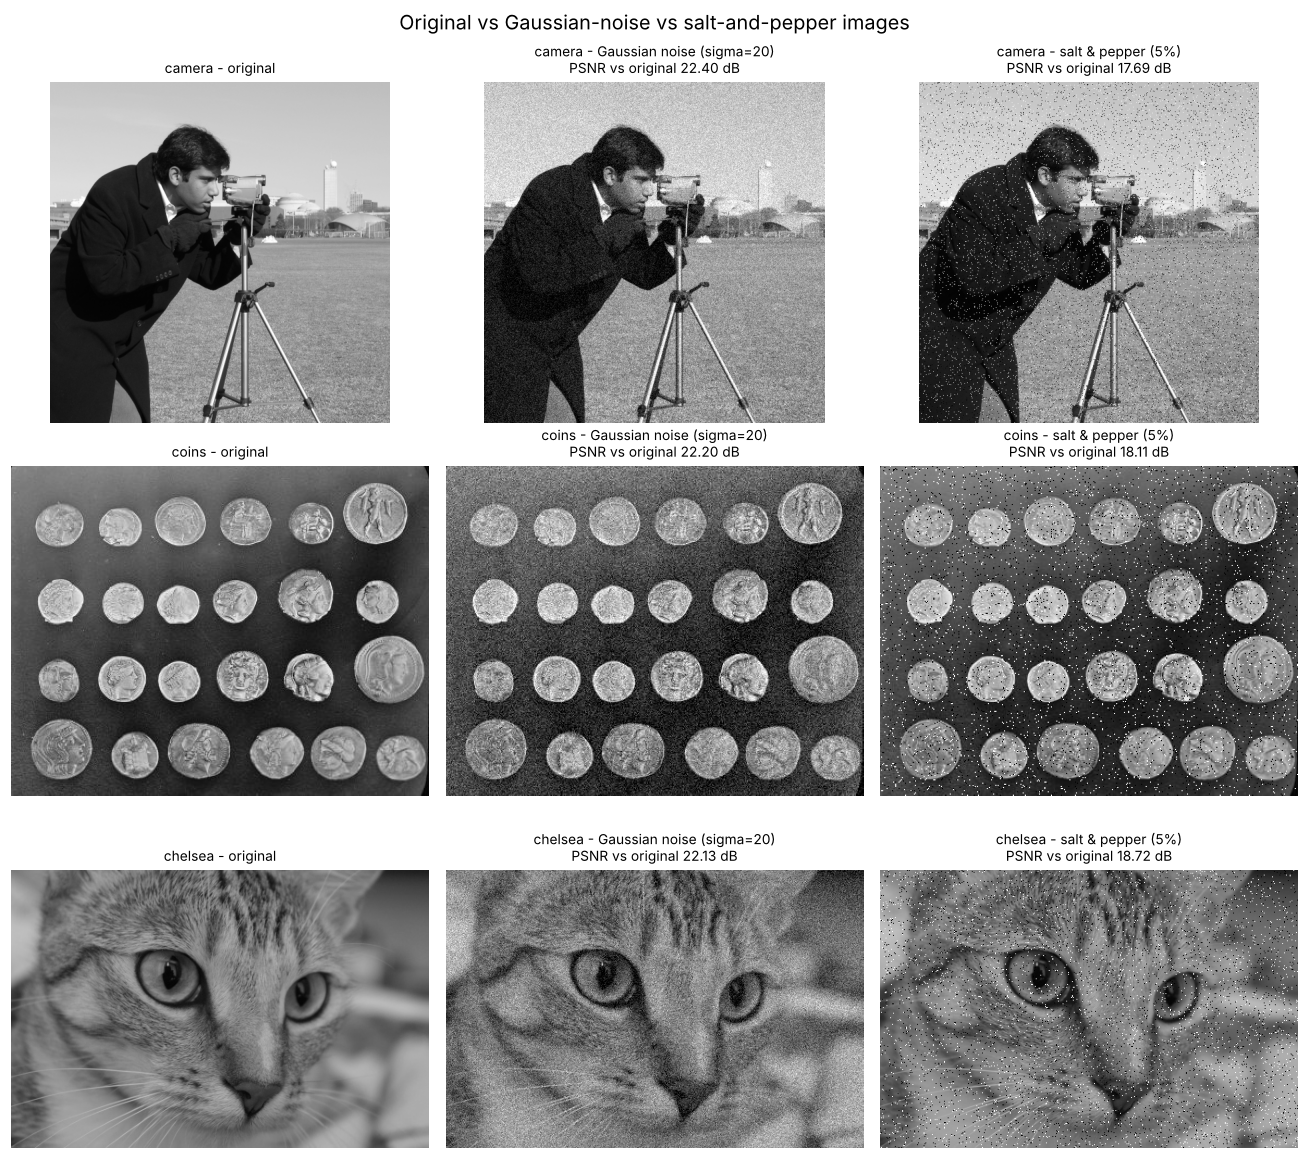

In [5]:
def show(ax, im, title):
    ax.imshow(im, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title, fontsize=9)
    ax.axis('off')

fig, axes = plt.subplots(3, 3, figsize=(12, 11))
for r, name in enumerate(originals):
    show(axes[r, 0], originals[name], f'{name} - original')
    show(axes[r, 1], noisy[(name, 'gaussian')],
         f'{name} - Gaussian noise (sigma=20)\nPSNR vs original {psnr(originals[name], noisy[(name, "gaussian")]):.2f} dB')
    show(axes[r, 2], noisy[(name, 'salt&pepper')],
         f'{name} - salt & pepper (5%)\nPSNR vs original {psnr(originals[name], noisy[(name, "salt&pepper")]):.2f} dB')
plt.suptitle('Original vs Gaussian-noise vs salt-and-pepper images', fontsize=13)
plt.tight_layout()
plt.show()

## 3. Filters (mean, Gaussian, median)
* **Mean:** all weights equal to 1/size² (sum = 1, R3). Applied with my `conv2d_loop` and with `cv2.blur`.
* **Gaussian:** discrete Gaussian weights, built as the outer product of OpenCV's 1-D kernel (`cv2.getGaussianKernel(k, 0)`): 3×3 = (1-2-1)ᵀ(1-2-1)/16, 5×5 = (1-4-6-4-1)ᵀ(1-4-6-4-1)/256, 7×7 = (2-7-14-18-14-7-2)ᵀ(2-7-14-18-14-7-2)/4096 — applied with `cv2.GaussianBlur` (with σ=0 OpenCV uses exactly these built-in kernels, so my kernels and OpenCV's agree).
* **Median:** middle value of the sorted neighbourhood, `cv2.medianBlur`.
* Even kernel sizes are rejected everywhere (R4).

In [6]:
def mean_kernel(k):
    check_odd(k)
    return np.full((k, k), 1.0 / k ** 2)

def gaussian_kernel(k):
    check_odd(k)
    v = cv2.getGaussianKernel(k, 0).ravel()      # OpenCV's fixed 1-D Gaussian for sizes 3/5/7 (sigma = 0)
    K = np.outer(v, v)
    return K / K.sum()                           # R3: weights sum to 1

def mean_filter(img, k):      check_odd(k); return cv2.blur(img, (k, k))
def gaussian_filter(img, k):  check_odd(k); return cv2.GaussianBlur(img, (k, k), 0)
def median_filter(img, k):    check_odd(k); return cv2.medianBlur(img, k)

FILTERS = {'mean': mean_filter, 'gaussian': gaussian_filter, 'median': median_filter}
SIZES = (3, 5, 7)

# R3: print each smoothing kernel's weight sum and confirm it equals 1 BEFORE using it
print('R3 - kernel weight sums:')
for k in SIZES:
    for nm, K in (('mean', mean_kernel(k)), ('gaussian', gaussian_kernel(k))):
        s = K.sum()
        assert np.isclose(s, 1.0)
        print(f'  {nm:8s} {k}x{k}: sum = {s:.12f}  -> equals 1: {np.isclose(s, 1.0)}')
print('\n3x3 Gaussian kernel * 16 =\n', (gaussian_kernel(3) * 16).astype(int))

R3 - kernel weight sums:
  mean     3x3: sum = 1.000000000000  -> equals 1: True
  gaussian 3x3: sum = 1.000000000000  -> equals 1: True
  mean     5x5: sum = 1.000000000000  -> equals 1: True
  gaussian 5x5: sum = 1.000000000000  -> equals 1: True
  mean     7x7: sum = 1.000000000000  -> equals 1: True
  gaussian 7x7: sum = 1.000000000000  -> equals 1: True

3x3 Gaussian kernel * 16 =
 [[1 2 1]
 [2 4 2]
 [1 2 1]]


In [7]:
# Does cv2.GaussianBlur really use my binomial kernel?  Compare against my own conv2d_loop on a real image.
for k in SIZES:
    mine = to_uint8(conv2d_loop(camera, gaussian_kernel(k)))
    ref  = gaussian_filter(camera, k)
    print(f'Gaussian {k}x{k}: conv2d_loop vs cv2.GaussianBlur, largest difference = {np.abs(mine.astype(int) - ref.astype(int)).max()} grey level(s)')

Gaussian 3x3: conv2d_loop vs cv2.GaussianBlur, largest difference = 1 grey level(s)


Gaussian 5x5: conv2d_loop vs cv2.GaussianBlur, largest difference = 1 grey level(s)


Gaussian 7x7: conv2d_loop vs cv2.GaussianBlur, largest difference = 1 grey level(s)


### 3.1 Mean filter: own `conv2d_loop` vs `cv2.blur` (must agree within rounding)

In [8]:
print('Mean filter, conv2d_loop vs cv2.blur on every noisy image (largest abs difference in grey levels):')
for (name, nt), im in noisy.items():
    row = []
    for k in SIZES:
        a = to_uint8(conv2d_loop(im, mean_kernel(k)))
        b = mean_filter(im, k)
        d = np.abs(a.astype(int) - b.astype(int)).max()
        assert d <= 1, 'mean filter mismatch beyond rounding'
        row.append(f'{k}x{k}: {d}')
    print(f'  {name:8s} {nt:12s} ' + '   '.join(row))

Mean filter, conv2d_loop vs cv2.blur on every noisy image (largest abs difference in grey levels):


  camera   gaussian     3x3: 0   5x5: 0   7x7: 0


  camera   salt&pepper  3x3: 0   5x5: 0   7x7: 0


  coins    gaussian     3x3: 0   5x5: 0   7x7: 0


  coins    salt&pepper  3x3: 0   5x5: 0   7x7: 0


  chelsea  gaussian     3x3: 0   5x5: 0   7x7: 0


  chelsea  salt&pepper  3x3: 0   5x5: 0   7x7: 0


### 3.2 Apply every filter at 3×3, 5×5 and 7×7 to every noisy image

In [9]:
results = {}                                      # (image, noise, filter, k) -> uint8 result
for (name, nt), im in noisy.items():
    for fn, f in FILTERS.items():
        for k in SIZES:
            results[(name, nt, fn, k)] = f(im, k)

# Metrics always measured against the CLEAN original (R6)
print('PSNR (dB) vs CLEAN original, 3x3 filters:')
for (name, nt), im in noisy.items():
    vals = '   '.join(f'{fn}={psnr(originals[name], results[(name, nt, fn, 3)]):6.2f}' for fn in FILTERS)
    print(f'  {name:8s} {nt:12s} noisy={psnr(originals[name], im):6.2f}   {vals}')

PSNR (dB) vs CLEAN original, 3x3 filters:
  camera   gaussian     noisy= 22.40   mean= 27.37   gaussian= 27.99   median= 26.95
  camera   salt&pepper  noisy= 17.69   mean= 24.83   gaussian= 24.71   median= 30.12
  coins    gaussian     noisy= 22.20   mean= 25.86   gaussian= 26.79   median= 26.00
  coins    salt&pepper  noisy= 18.11   mean= 24.10   gaussian= 24.36   median= 28.37
  chelsea  gaussian     noisy= 22.13   mean= 29.54   gaussian= 29.45   median= 28.26
  chelsea  salt&pepper  noisy= 18.72   mean= 26.98   gaussian= 26.48   median= 33.90


## 4. Rule compliance checks (R1 – R5)

In [10]:
# R1 & R2: every filtered output is uint8, inside 0-255 and the same shape as its input
ok = True
for (name, nt, fn, k), out in results.items():
    src = noisy[(name, nt)]
    cond = (out.dtype == np.uint8) and (out.min() >= 0) and (out.max() <= 255) and (out.shape == src.shape)
    ok &= cond
print(f'R1/R2: all {len(results)} filtered outputs are uint8, within 0-255 and same shape as input -> {ok}')
assert ok

# R3 was verified above (all smoothing kernels sum to 1).

# R4: even kernel sizes are rejected
print('\nR4 - even kernel size must be rejected:')
try:
    cv2.medianBlur(camera, 4)
except cv2.error as e:
    print('  cv2.medianBlur(img, 4) raised cv2.error  ->  rejected as required')
for f_name, f in FILTERS.items():
    try:
        f(camera, 4)
    except ValueError as e:
        print(f'  my {f_name}_filter(img, 4) raised ValueError: {e}')

# R5: regenerate the noise (as a fresh run would) and compare with the first run
print('\nR5 - reproducibility with seed=5:')
for name, im in originals.items():
    g2 = add_gaussian_noise(im, sigma=20, seed=5)
    s2 = add_salt_pepper(im, amount=0.05, seed=5)
    print(f'  {name:8s} gaussian identical: {np.array_equal(g2, noisy[(name, "gaussian")])}   '
          f'salt&pepper identical: {np.array_equal(s2, noisy[(name, "salt&pepper")])}')
    assert np.array_equal(g2, noisy[(name, 'gaussian')]) and np.array_equal(s2, noisy[(name, 'salt&pepper')])

R1/R2: all 54 filtered outputs are uint8, within 0-255 and same shape as input -> True

R4 - even kernel size must be rejected:
  cv2.medianBlur(img, 4) raised cv2.error  ->  rejected as required
  my mean_filter(img, 4) raised ValueError: Kernel size must be odd (3, 5 or 7), got 4
  my gaussian_filter(img, 4) raised ValueError: Kernel size must be odd (3, 5 or 7), got 4
  my median_filter(img, 4) raised ValueError: Kernel size must be odd (3, 5 or 7), got 4

R5 - reproducibility with seed=5:
  camera   gaussian identical: True   salt&pepper identical: True
  coins    gaussian identical: True   salt&pepper identical: True
  chelsea  gaussian identical: True   salt&pepper identical: True


## 5. Dry-run exercises (hand calculation + matching code output)

### Exercise 1 — Spike response
Neighbourhood (one bright pixel in a flat region):

```
[[ 40,  40,  40],
 [ 40, 255,  40],
 [ 40,  40,  40]]
```

**(a) 3×3 mean kernel** (all weights 1/9):
* Sum of the eight 40s = 8 × 40 = 320
* Total sum = 320 + 255 = 575
* Centre output = 575 / 9 = **63.89 ≈ 64**

**(b) 3×3 Gaussian kernel (1-2-1 ÷ 16)**, weights `[[1,2,1],[2,4,2],[1,2,1]] / 16`:
* Corners: 4 corners × (1 × 40) = 160
* Edge-neighbours: 4 × (2 × 40) = 320
* Centre: 4 × 255 = 1020
* Weighted sum = 160 + 320 + 1020 = 1500
* Centre output = 1500 / 16 = **93.75 ≈ 94**

**(c) 3×3 median**:
* Sorted values: 40, 40, 40, 40, 40, 40, 40, 40, 255
* 5th (middle) of 9 values = **40**

In [11]:
spike = np.array([[40, 40, 40], [40, 255, 40], [40, 40, 40]], dtype=np.uint8)

mean_c = np.sum(spike * mean_kernel(3))
gk16 = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]])
gauss_sum = np.sum(spike.astype(int) * gk16)
gauss_c = gauss_sum / 16
median_c = np.median(spike)

print(f'Mean   : sum = {spike.astype(int).sum()}  ->  {spike.astype(int).sum()}/9 = {mean_c:.4f}  (uint8: {int(np.round(mean_c))})')
print(f'Gauss  : corners={4*40}, edges={4*2*40}, centre={4*255}, total={gauss_sum}  ->  {gauss_sum}/16 = {gauss_c:.4f}  (uint8: {int(np.round(gauss_c))})')
print(f'Median : sorted = {sorted(spike.flatten().tolist())}  ->  middle = {median_c:.0f}')

# cross-check with the notebook's own conv2d_loop and with OpenCV at the centre pixel
print('\nCross-check at the centre pixel:')
print('  conv2d_loop mean     :', round(conv2d_loop(spike, mean_kernel(3))[1, 1], 4))
print('  conv2d_loop gaussian :', round(conv2d_loop(spike, gaussian_kernel(3))[1, 1], 4))
print('  cv2.medianBlur       :', cv2.medianBlur(spike, 3)[1, 1])
assert np.isclose(mean_c, 575 / 9) and np.isclose(gauss_c, 93.75) and median_c == 40

Mean   : sum = 575  ->  575/9 = 63.8889  (uint8: 64)
Gauss  : corners=160, edges=320, centre=1020, total=1500  ->  1500/16 = 93.7500  (uint8: 94)
Median : sorted = [40, 40, 40, 40, 40, 40, 40, 40, 255]  ->  middle = 40

Cross-check at the centre pixel:
  conv2d_loop mean     : 63.8889
  conv2d_loop gaussian : 93.75
  cv2.medianBlur       : 40


### Exercise 2 — Reflect padding at a corner
Image:

```
[[10, 20, 30],
 [40, 50, 60],
 [70, 80, 90]]
```
With `np.pad(..., mode='reflect')` the border is mirrored **without repeating the edge pixel**, so the row/column at index −1 equals the row/column at index 1. The 3×3 neighbourhood of pixel (0, 0) is therefore

```
[[50, 40, 50],
 [20, 10, 20],
 [50, 40, 50]]
```
* Row sums: 50+40+50 = 140, 20+10+20 = 50, 50+40+50 = 140
* Total = 140 + 50 + 140 = 330
* Mean = 330 / 9 = **36.67 ≈ 37**

In [12]:
img3 = np.array([[10, 20, 30], [40, 50, 60], [70, 80, 90]], dtype=np.uint8)

padded = np.pad(img3, 1, mode='reflect')
window = padded[0:3, 0:3]                       # neighbourhood of pixel (0, 0) in the padded image
print('Padded image:\n', padded)
print('\nPadded 3x3 neighbourhood of (0,0):\n', window)
print(f'\nSum = {window.sum()},  mean = {window.sum()}/9 = {window.sum()/9:.4f}  (uint8: {int(np.round(window.sum()/9))})')

print('\nCross-check at (0,0):')
print('  conv2d_loop mean :', round(conv2d_loop(img3, mean_kernel(3))[0, 0], 4))
print('  cv2.blur         :', cv2.blur(img3, (3, 3))[0, 0])
assert window.sum() == 330 and np.isclose(window.sum() / 9, 330 / 9)

Padded image:
 [[50 40 50 60 50]
 [20 10 20 30 20]
 [50 40 50 60 50]
 [80 70 80 90 80]
 [50 40 50 60 50]]

Padded 3x3 neighbourhood of (0,0):
 [[50 40 50]
 [20 10 20]
 [50 40 50]]

Sum = 330,  mean = 330/9 = 36.6667  (uint8: 37)

Cross-check at (0,0):
  conv2d_loop mean : 36.6667
  cv2.blur         : 37


## 6. Demonstration and comparison figures
### 6.1 Mean vs Gaussian vs Median (3×3) on every noisy image
Each panel title shows the PSNR measured against the **clean original** (R6), never against the noisy image.

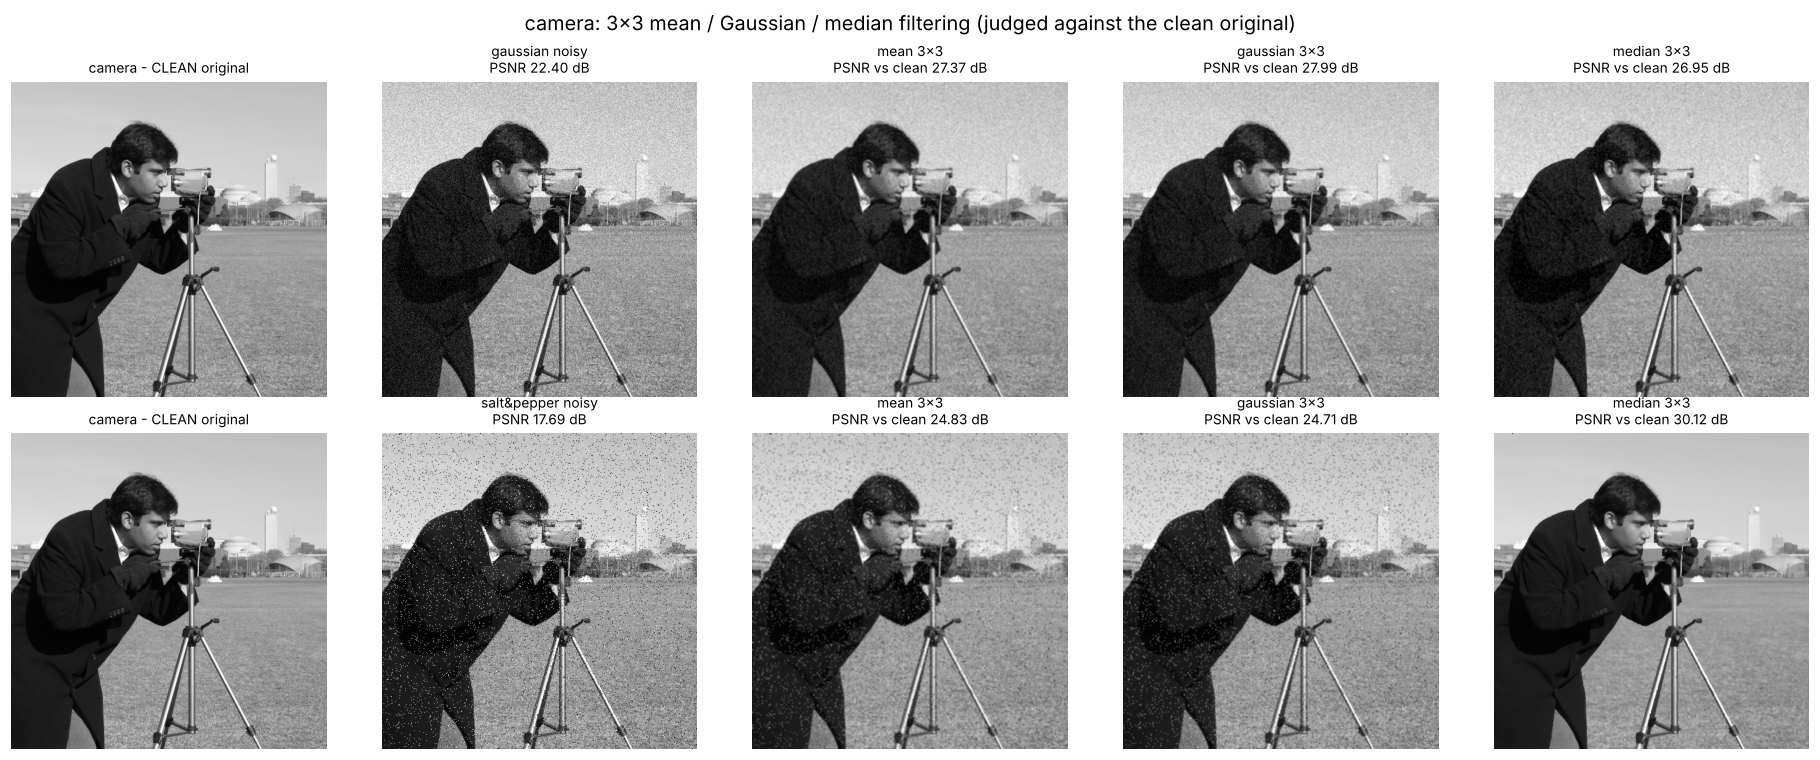

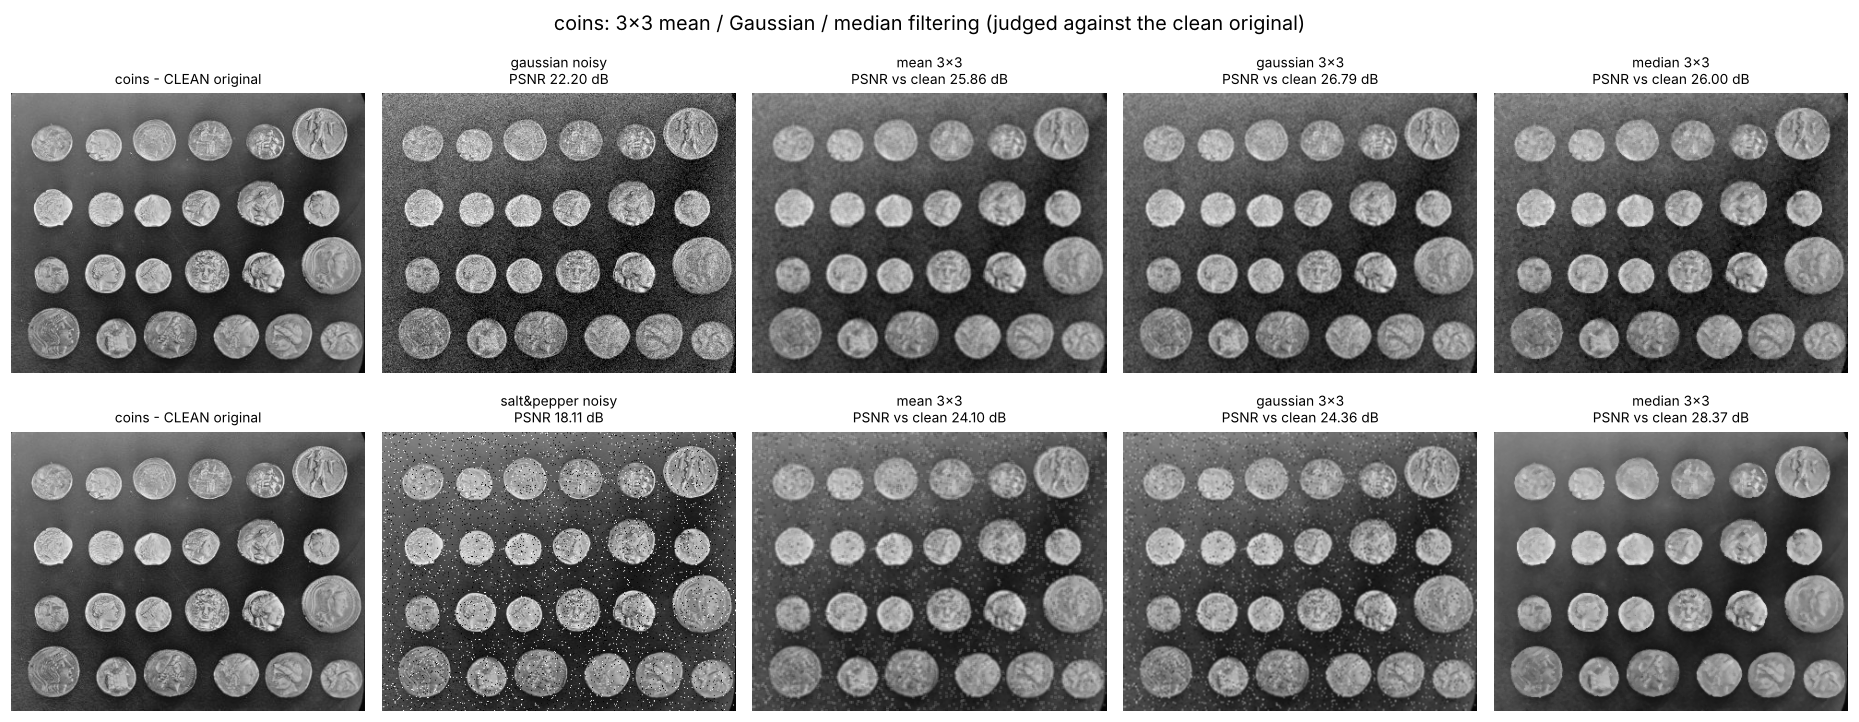

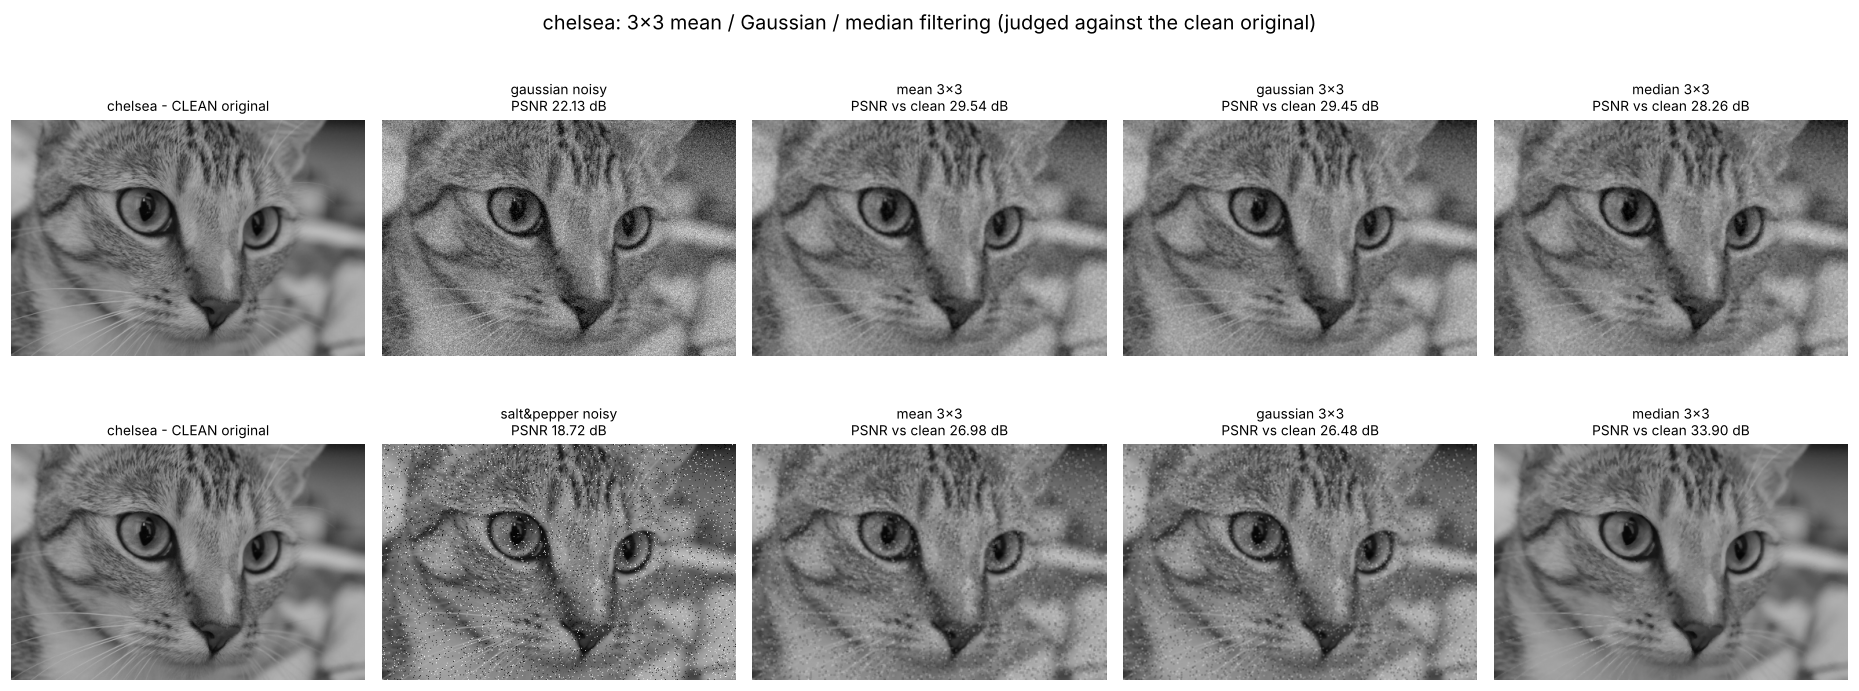

In [13]:
for name in originals:
    fig, axes = plt.subplots(2, 5, figsize=(17, 7))
    for r, nt in enumerate(('gaussian', 'salt&pepper')):
        show(axes[r, 0], originals[name], f'{name} - CLEAN original')
        nz = noisy[(name, nt)]
        show(axes[r, 1], nz, f'{nt} noisy\nPSNR {psnr(originals[name], nz):.2f} dB')
        for c, fn in enumerate(FILTERS, start=2):
            out = results[(name, nt, fn, 3)]
            show(axes[r, c], out, f'{fn} 3x3\nPSNR vs clean {psnr(originals[name], out):.2f} dB')
    plt.suptitle(f'{name}: 3x3 mean / Gaussian / median filtering (judged against the clean original)', fontsize=13)
    plt.tight_layout()
    plt.show()

### 6.2 Kernel-size grid (filter × size) on the noisiest image

Noisiest image (lowest PSNR against its clean original): camera / salt&pepper  (17.69 dB)


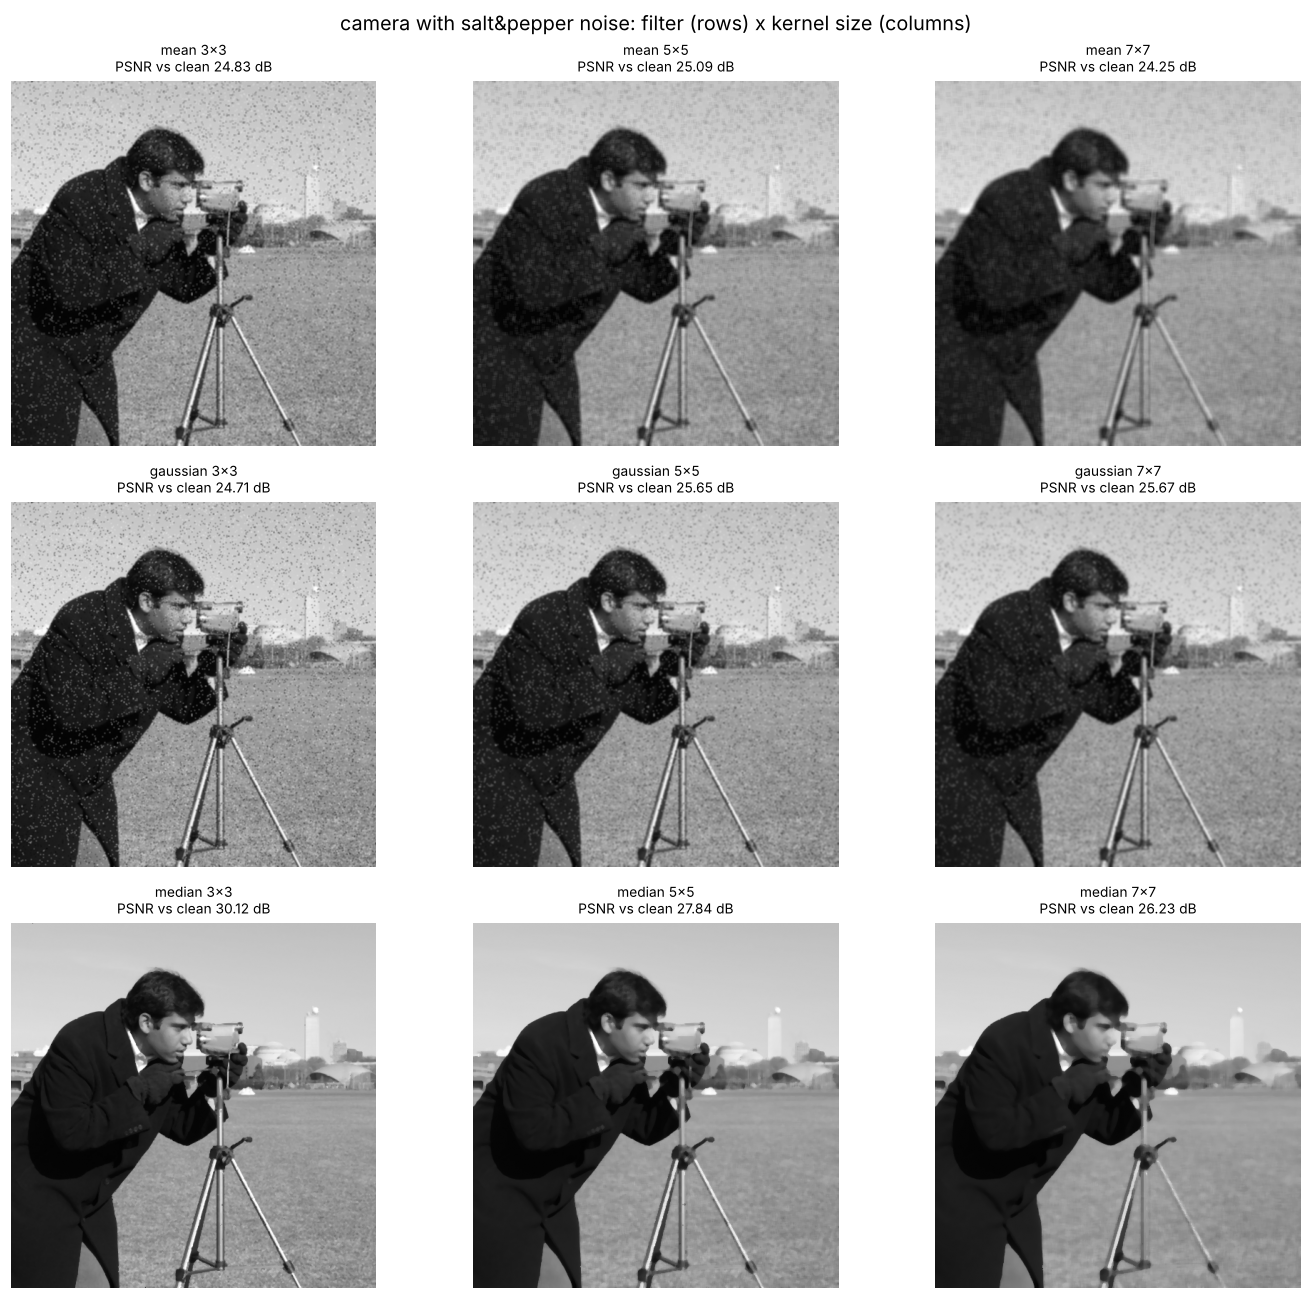


PSNR (dB) against the CLEAN original, all kernel sizes, noisiest image:
  mean     3x3= 24.83   5x5= 25.09   7x7= 24.25
  gaussian 3x3= 24.71   5x5= 25.65   7x7= 25.67
  median   3x3= 30.12   5x5= 27.84   7x7= 26.23


In [14]:
noisiest = min(noisy, key=lambda key: psnr(originals[key[0]], noisy[key]))
nm, nt = noisiest
print(f'Noisiest image (lowest PSNR against its clean original): {nm} / {nt}  ({psnr(originals[nm], noisy[noisiest]):.2f} dB)')

fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for r, fn in enumerate(FILTERS):
    for c, k in enumerate(SIZES):
        out = results[(nm, nt, fn, k)]
        show(axes[r, c], out, f'{fn} {k}x{k}\nPSNR vs clean {psnr(originals[nm], out):.2f} dB')
plt.suptitle(f'{nm} with {nt} noise: filter (rows) x kernel size (columns)', fontsize=13)
plt.tight_layout()
plt.show()

print('\nPSNR (dB) against the CLEAN original, all kernel sizes, noisiest image:')
for fn in FILTERS:
    print(f'  {fn:8s} ' + '   '.join(f'{k}x{k}={psnr(originals[nm], results[(nm, nt, fn, k)]):6.2f}' for k in SIZES))

### 6.3 Extra evidence used in the observations: a sharp edge and fine detail

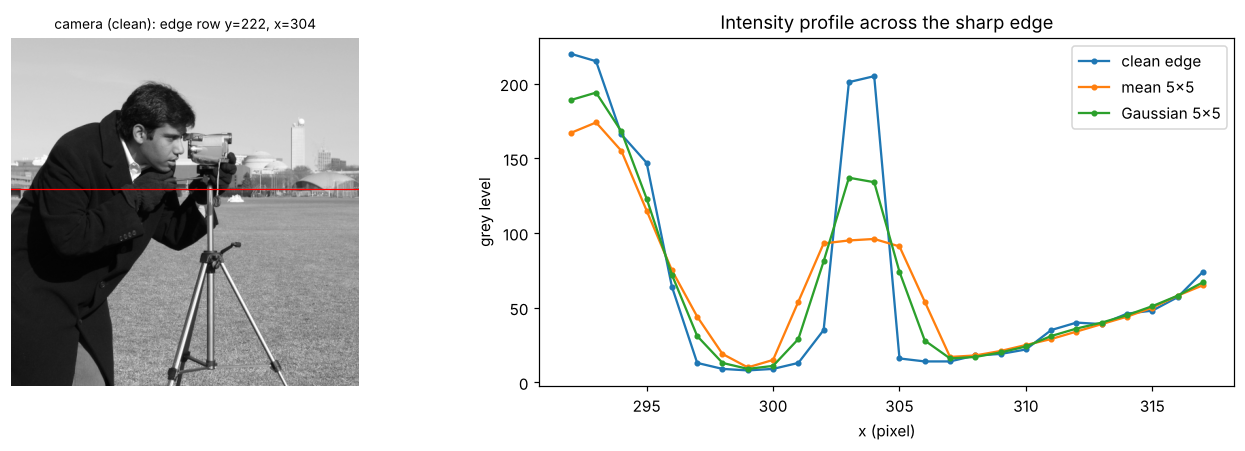

profile         steepest step    pixels in 10-90% transition
clean edge              189.0                             11
mean 5x5                 40.0                             17
Gaussian 5x5             60.0                             17

Fine-detail measure (variance of Laplacian) - clean original vs Gaussian-noise result filtered at 3x3 and 7x7:
  camera   clean=   1133.2  mean: 3x3=   226.5  7x7=    19.6   gaussian: 3x3=   251.8  7x7=    25.1   median: 3x3=   656.5  7x7=   113.7   
  coins    clean=   1911.6  mean: 3x3=   287.8  7x7=    24.5   gaussian: 3x3=   348.0  7x7=    35.8   median: 3x3=   918.8  7x7=   187.3   
  chelsea  clean=    402.2  mean: 3x3=   190.0  7x7=    15.8   gaussian: 3x3=   206.9  7x7=    14.6   median: 3x3=   480.8  7x7=    48.3   


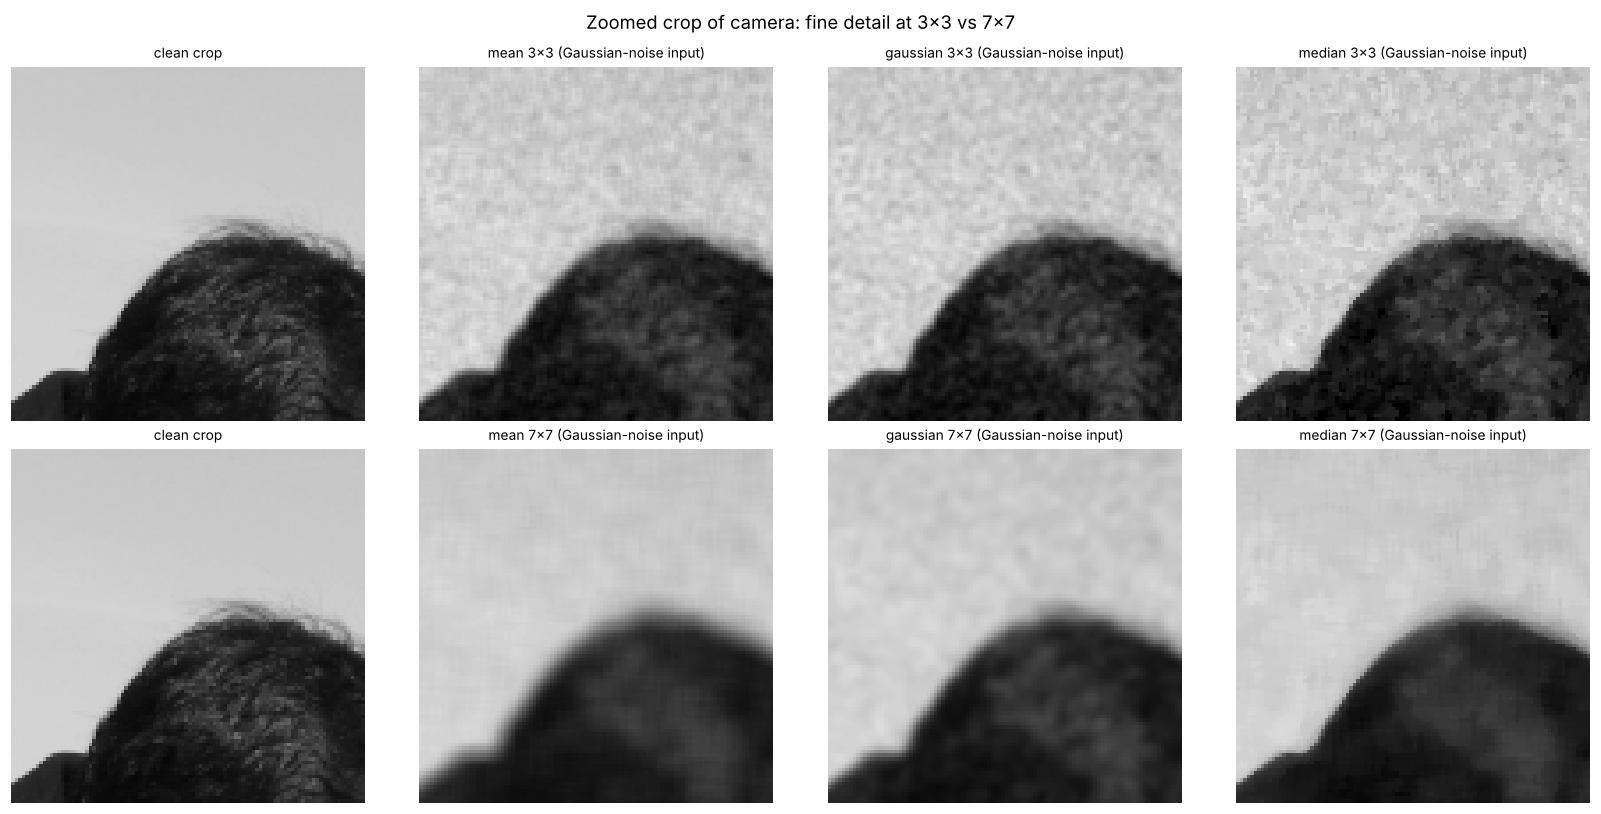

In [15]:
# --- Sharp edge: strongest horizontal edge in the clean `camera` image, mean 5x5 vs Gaussian 5x5 (clean input) ---
clean = originals['camera']
gx = np.abs(np.diff(clean.astype(np.float64), axis=1))
gx[:, :10] = 0; gx[:, -10:] = 0
ey, ex = np.unravel_index(np.argmax(gx), gx.shape)
xs = np.arange(ex - 12, ex + 14)
prof = {'clean edge': clean[ey, xs],
        'mean 5x5': mean_filter(clean, 5)[ey, xs],
        'Gaussian 5x5': gaussian_filter(clean, 5)[ey, xs]}

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].imshow(clean, cmap='gray', vmin=0, vmax=255)
ax[0].axhline(ey, color='r', lw=0.8); ax[0].set_title(f'camera (clean): edge row y={ey}, x={ex}', fontsize=9); ax[0].axis('off')
for lab, p in prof.items():
    ax[1].plot(xs, p, marker='o', ms=3, label=lab)
ax[1].set_title('Intensity profile across the sharp edge'); ax[1].set_xlabel('x (pixel)'); ax[1].set_ylabel('grey level'); ax[1].legend()
plt.tight_layout(); plt.show()

def maxgrad(p): return np.abs(np.diff(p.astype(np.float64))).max()
def width_1090(p):
    p = p.astype(np.float64); lo, hi = p.min(), p.max()
    t10, t90 = lo + 0.1 * (hi - lo), lo + 0.9 * (hi - lo)
    up = p[-1] > p[0]
    idx = np.where((p > t10) & (p < t90))[0]
    return len(idx)
print(f'{"profile":14s} {"steepest step":>14s} {"pixels in 10-90% transition":>30s}')
for lab, p in prof.items():
    print(f'{lab:14s} {maxgrad(p):14.1f} {width_1090(p):30d}')

# --- Fine detail: Laplacian variance (a sharpness / detail measure) of the clean image vs 3x3 and 7x7 filtered results ---
def sharp(im): return cv2.Laplacian(im, cv2.CV_64F).var()
print('\nFine-detail measure (variance of Laplacian) - clean original vs Gaussian-noise result filtered at 3x3 and 7x7:')
for name in originals:
    row = f'  {name:8s} clean={sharp(originals[name]):9.1f}  '
    for fn in FILTERS:
        row += f'{fn}: 3x3={sharp(results[(name, "gaussian", fn, 3)]):8.1f}  7x7={sharp(results[(name, "gaussian", fn, 7)]):8.1f}   '
    print(row)

# --- zoomed crop of fine detail (camera: tripod/camera region) at 3x3 vs 7x7 ---
y0, y1, x0, x1 = 20, 120, 140, 240
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
show(axes[0, 0], originals['camera'][y0:y1, x0:x1], 'clean crop'); show(axes[1, 0], originals['camera'][y0:y1, x0:x1], 'clean crop')
for c, fn in enumerate(FILTERS, start=1):
    show(axes[0, c], results[('camera', 'gaussian', fn, 3)][y0:y1, x0:x1], f'{fn} 3x3 (Gaussian-noise input)')
    show(axes[1, c], results[('camera', 'gaussian', fn, 7)][y0:y1, x0:x1], f'{fn} 7x7 (Gaussian-noise input)')
plt.suptitle('Zoomed crop of camera: fine detail at 3x3 vs 7x7', fontsize=12); plt.tight_layout(); plt.show()

## 7. Observations (answered from the figures above; every filtered image is judged against the **clean original**, R6)

**Q1. Which filter looks best on Gaussian noise, and which looks worst?**
*Best: the Gaussian filter (3×3); worst: the median filter.* In the first (Gaussian-noise) row of the `camera` figure, the Gaussian 3×3 result has the highest PSNR against the **clean** original (27.99 dB, versus 27.37 dB for mean and 26.95 dB for median), and the same ordering holds for `coins` (26.79 / 25.86 / 26.00 dB for Gaussian / mean / median). On `chelsea` mean and Gaussian are practically tied (29.54 vs 29.45 dB) and the median is again lowest (28.26 dB). The reason is visible in the dark coat and the sky of the `camera` panels: Gaussian noise changes *every* pixel a little, so averaging filters cancel it, while the median replaces each pixel by one of the noisy neighbours and leaves a mottled, grainy texture on the grass and coat. (On `coins` the mean is marginally the lowest, by 0.14 dB, so the "worst" filter for Gaussian noise is median or mean depending on the image, and the difference between them is small.)

**Q2. Which filter looks best on salt-and-pepper noise, and why do the other two fail?**
*Best: the median filter.* In the second row of the `camera` figure the median 3×3 output is almost free of the black/white dots (30.12 dB against the clean original), whereas mean (24.83 dB) and Gaussian (24.71 dB) still show grey blotches across the sky and on the coat. The same holds for `coins` (28.37 vs 24.10 / 24.36 dB) and `chelsea` (33.90 vs 26.98 / 26.48 dB). **Why mean and Gaussian fail:** they are *linear* — an extreme pixel is not rejected, only spread over its neighbours. This is exactly Dry-run Exercise 1: one 255 spike among 40s moves the 3×3 mean centre from 40 to 63.89 and the Gaussian centre to 93.75, i.e. the spike leaks into the output as a blurred grey spot. The **median** ignores the value of an outlier and only uses its rank: the 255 is sorted to the end of the list and the middle value stays 40.

**Q3. How do mean and Gaussian compare on a sharp edge?**
In the edge-profile figure (red row through the strongest edge of the clean `camera` image) the clean edge jumps by 189 grey levels in a single pixel step. After a 5×5 mean the steepest step falls to 40 and after a 5×5 Gaussian to 60, and both spread the edge over about 17 pixels (10–90 % transition). The mean spreads the edge as an almost straight ramp, because all 25 neighbours count equally, while the Gaussian is centre-weighted, so it keeps a steeper middle section and a smoother, less "boxy" transition. This is why on `coins`, which is full of sharp coin outlines, the Gaussian 3×3 (26.79 dB) beats the mean 3×3 (25.86 dB) against the clean original. Both blur the edge; the Gaussian blurs it a little less harshly.

**Q4. What happens to fine detail at 7×7?**
It is largely destroyed. In the kernel-size grid (`camera`, salt-and-pepper), the thin tripod legs and the buildings on the horizon (top-right of the picture) are clear at 3×3 but are faint and smeared in the mean 7×7 and Gaussian 7×7 panels, and even the median 7×7 rounds them off into a smooth, "painted" look. The detail measure (variance of the Laplacian) in the figure section above supports this: for `camera` it falls from 1133 (clean) to about 20 (mean 7×7) and 25 (Gaussian 7×7), and to 114 for the median 7×7. The PSNR against the clean original also shows over-smoothing: the median drops steadily from 30.12 dB (3×3) to 27.84 dB (5×5) to 26.23 dB (7×7), and the mean falls from 25.09 dB (5×5) to 24.25 dB (7×7): beyond a point, the blur costs more than the noise removal gains.

**Q5. Why must the kernel size be odd?**
An odd kernel has a single **centre** pixel, so the output pixel sits exactly on the input pixel being processed (e.g. the 255 in the middle of the 3×3 window in Exercise 1). An even kernel (4×4) has no centre; the output would be shifted by half a pixel and the padding would be asymmetric, so the image would drift and R1 (same size, aligned) could not be met cleanly. Padding is also symmetric with an odd size: `k // 2` pixels on each side (1 for 3×3, 3 for 7×7). For the **median**, an odd k gives k² (an odd count of values), so there is one unique middle element; with an even count there are two middle values and an extra rule would be needed. OpenCV enforces this: the compliance check above shows `cv2.medianBlur(img, 4)` raising an error.

## 8. Viva preparation

**1. What is a kernel?** A small matrix of weights (e.g. 3×3) that slides over the image; each output pixel is the weighted sum of the pixels under the kernel. The weights decide the effect: equal weights → mean blur, bell-shaped weights → Gaussian blur.

**2. Apply a 3×3 mean kernel to a 3×3 window given on the spot.** Add all 9 values and divide by 9. For `[[40,40,40],[40,255,40],[40,40,40]]`: (8 × 40 + 255) / 9 = 575 / 9 = 63.89 ≈ 64.

**3. Why does the median remove a 255 spike but the mean does not?** The mean uses the *value* of every neighbour, so a 255 adds 255/9 ≈ 28 to the sum (output 63.89 instead of 40). The median only uses *rank*: the spike is sorted to the end of the list, and the middle (5th) value remains 40.

**4. Why do the Gaussian weights sum to 16, and why divide by it?** The 1-D weights are 1, 2, 1 (sum 4); the 2-D kernel is their outer product, so the sum is 4 × 4 = 16. Dividing by 16 makes the weights sum to 1 (R3), so a flat region keeps its brightness (a flat area of 100 gives 1600/16 = 100) and the image does not get brighter or darker.

**5. Why do we pad the border before filtering?** Pixels at the border do not have a full neighbourhood. Padding (here with reflect padding) supplies the missing neighbours so every pixel can be filtered and the output keeps the same size as the input (R1); without it the image would shrink. Reflect padding avoids the dark edge that zero padding would create (Exercise 2: the corner's neighbourhood becomes `[[50,40,50],[20,10,20],[50,40,50]]` → 36.67).

**6. Which filter for salt-and-pepper noise, and why?** The median filter: the noisy pixels are extreme outliers (0 or 255), which the median discards by ranking, while keeping edges much better than the mean (see Q2: 30.12 dB median vs 24.83 dB mean on `camera`).

## 9. Final integrity check
The original test images must be exactly as loaded at the start of the notebook.

In [16]:
print('Originals unchanged:', all(np.array_equal(originals[k], _orig_copy[k]) for k in originals))

Originals unchanged: True
